# Movimiento browniano: cuatro mediciones y seis formas de sacar la deriva

Se caracteriza el movimiento browniano de beads de látex libres con las cuatro grabaciones disponibles y se comparan distintas formas de sacar la deriva (el corrimiento lento de la muestra, que no es browniano).

| Medición | Video | Cuadros | Conversión a trayectorias |
|---|---|---|---|
| BROWNIANO 1 (nuestra) | ThorCam, 31 TIFF | 5102 a 10.02 cuadros/s (509 s) | parámetros por defecto |
| BROWNIANO 2 (nuestra) | ThorCam, 13 TIFF | 2121 a 10.02 cuadros/s (212 s) | parámetros por defecto |
| GROS BROWNIANO (otro grupo) | AVI | 600 a 15.0 cuadros/s (40 s) | parámetros por defecto |
| CHICAS BROWNIANO (otro grupo) | MP4 de 1 MB | 229 cuadros distintos en 11.7 s | Radio de la bead 22 px y Umbral 6 (ver abajo) |

Las trayectorias salen de `TouchDesigner/herramientas/convertir.py` y están en `datos/<medición>/`. Los pasos intermedios del análisis de imagen de cada una están en `figuras/<medición>/pasos/`. El radio aparente de cada partícula lo mide `analisis/medir_radios.py` sobre el video (`datos/<medición>/radios.csv`).

**Qué está medido y qué está supuesto**

- **Escala.** 94.61 ± 0.2 nm/px, medida con la retícula de 0.01 mm. Vale para las dos grabaciones nuestras. Para las de los otros grupos **se supone la misma** (mismo equipo y misma cámara de 1280 × 1024). El MP4 de CHICAS mide 1440 × 1080 con bandas negras: es la imagen de 1280 × 1024 agrandada 1080/1024, así que su escala supuesta es 94.61 × 1024/1080 = 89.70 nm por px del video.
- **Tiempo.** Los TIFF de ThorCam no traen el tiempo de cada cuadro: es índice / 10.02 cuadros/s. Con las fechas de los archivos, cada parte de 167 cuadros da 10.0215 ± 0.004 cuadros/s en las dos grabaciones. El AVI usa el fps del archivo (15.001). El MP4 se discute abajo.
- **Temperatura.** No se anotó: se supone 23 ± 3 °C.
- **Muestras** (cuaderno): BROWNIANO 1, "0.25 ml glicerina, 1 ml agua?" (con signo de pregunta); BROWNIANO 2, 60 ml de agua + 65 ml de glicerina. De los otros grupos no se sabe. Beads de látex de 3 µm de diámetro nominal, con otros tamaños mezclados.

Todo el notebook trabaja en µm y s.

In [1]:
from trayectorias import *
from pinzas import fisica
from scipy import stats, optimize
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)      # promedios de columnas vacías (huecos con NaN)

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE = "#2A9D8F", "#E76F51", "#264653"
SERIE3, SERIE4 = "#4C72B0", "#8172B2"            # azul y violeta de la paleta de seaborn de la guía
MARCA = dict(ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, zorder=3)
LEYENDA = dict(facecolor="white", framealpha=0.9)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

FIGURAS = os.path.join(RAIZ, "figuras", "BROWNIANO comparación")        # RAIZ = pinzas ópticas/
SALIDA = os.path.join(RAIZ, "datos", "BROWNIANO comparación")
os.makedirs(FIGURAS, exist_ok=True)
os.makedirs(SALIDA, exist_ok=True)

ESCALA, ERR_ESCALA = 0.09461, 0.0002     # µm por px del sensor (retícula): MEDIDA para las grabaciones nuestras
T_AMB, ERR_T = 296.15, 3.0               # K: 23 °C SUPUESTO, ± 3 °C
R_NOMINAL = 1.5                          # µm: radio nominal de las beads (3 µm de diámetro)
MAX_LAG = 30                             # retardo máximo del MSD, en cuadros
N_AJUSTE = 4                             # retardos que se usan para ajustar D
N_SIM = 40                               # repeticiones de cada simulación
rng = np.random.default_rng(2026)

# clases: lo que se ve en figuras/<medición>/radios/recortes.png (seis recortes de cada partícula). Lo que no
# está acá es una bead sola; después, por radio aparente: < 1.6 µm "chica", > 2.35 µm "agregado".
MEDICIONES = {
    "BROWNIANO 1": dict(escala=ESCALA, nuestra=True, largo_min=200, ventana=10.0, ventanas=[1, 2, 3, 5, 8, 12, 20, 40],
                        clases={6: "agregado", 40: "agregado", 42: "agregado",
                                24: "fuera de foco", 26: "fuera de foco", 27: "fuera de foco"}),
    "BROWNIANO 2": dict(escala=ESCALA, nuestra=True, largo_min=200, ventana=10.0, ventanas=[1, 2, 3, 5, 8, 12, 20, 40],
                        clases={3: "agregado", 34: "agregado", 15: "fuera de foco"}),
    "GROS BROWNIANO": dict(escala=ESCALA, nuestra=False, largo_min=200, ventana=10.0, ventanas=[1, 2, 3, 5, 8, 12, 20, 40],
                           clases={2: "con vecina", 15: "agregado"}),
    "CHICAS BROWNIANO": dict(escala=ESCALA * 1024 / 1080, nuestra=False, largo_min=100, ventana=4.0,
                             ventanas=[0.5, 1, 1.5, 2, 3, 4, 6, 10], clases={}),
}


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)


def archivo(nombre):
    return nombre.replace(" ", "_")

## 1. Los datos

Para cada medición:

- se descartan los puntos marcados como **colisión** (dos beads a menos de 2.5 radios: la posición es poco confiable);
- entran las trayectorias con al menos `largo_min` cuadros medidos (200, es decir 20 s en las nuestras y 13 s en GROS; 100 en CHICAS, que dura 11.7 s);
- una trayectoria es **confinada** (pegada al vidrio) si la pendiente log-log de su MSD, después de restarle su recta, es menor que 0.5; no entra en el análisis;
- cada partícula tiene una **clase** que sale de mirar sus imágenes (sección 2).

Tres decisiones sobre el tiempo y la conversión, que se anotan en `DUDAS browniano.md`:

- **BROWNIANO 1, pausa de escritura.** Las partes 26 y 27 del TIFF (cuadros 4342 a 4675) tardaron 3.7 s y 1.1 s más que las otras en escribirse: en ese tramo faltan cuadros y no se sabe dónde. Entre los cuadros 4414 y 4415 se corta una de las dos trayectorias que había y empiezan dos nuevas, que es lo que se espera si ahí faltan varios segundos. Se descartan esos 334 cuadros y al tiempo de los siguientes se le suman 4.79 s.
- **CHICAS, tiempo.** El MP4 está a 30 cuadros/s pero repite cuadros: el importador deja 229 distintos, con intervalos de 1 o 2 cuadros del contenedor (patrón 1, 1, 2) y 17 saltos más largos. La varianza del paso es la misma con intervalo 1 que con intervalo 2 (1.09 y 1.24 px²) y el doble en los saltos largos (2.5 px²): la cámara iba pareja a unos 22 cuadros/s y el contenedor solo cuantiza. Por eso el tiempo se regulariza (`tiempo_regular`): período constante entre saltos largos. Si en cambio no faltara ningún cuadro, serían 19.5 cuadros/s y $D$ bajaría 12 %.
- **CHICAS, detección.** Con los parámetros por defecto no se detectaba casi nada: las beads miden unos 44 px de diámetro en el video (Radio 22 en vez de 17) y el contraste después de sacar el fondo es bajo (Umbral 6 en vez de 12). Las trayectorias pegadas a las bandas negras se descartan.

In [2]:
def cargar_medicion(nombre):
    c = MEDICIONES[nombre]
    datos = cargar(os.path.join(RAIZ, "datos", nombre))
    tr = datos["tr"]
    n_total, n_col = len(tr), int(tr.colision.sum())
    tr.loc[tr.colision == 1, ["x_px", "y_px"]] = np.nan
    t, X, Y, ids, _ = matrices(datos, escala_um=c["escala"])              # µm
    if nombre == "BROWNIANO 1":                      # pausa de escritura: sin tiempo confiable
        X[4342:4676], Y[4342:4676] = np.nan, np.nan
        t = t.copy()
        t[4676:] += 4.79
    if nombre == "CHICAS BROWNIANO":
        t, _ = tiempo_regular(t)
        x_px = np.nanmean(X, 0) / c["escala"]
        X[:, (x_px < 115) | (x_px > 1325)] = np.nan   # pegadas a las bandas negras del video
        Y[~np.isfinite(X)] = np.nan
    largo = np.isfinite(X).sum(0) >= c["largo_min"]
    X, Y, ids = X[:, largo], Y[:, largo], ids[largo]
    rad = pd.read_csv(os.path.join(RAIZ, "datos", nombre, "radios.csv")).set_index("particula").reindex(ids)
    Rap, eRap = rad.r_borde_px.values * c["escala"], rad.err_r_borde_px.values * c["escala"]
    r = analizar_deriva(t, X, Y, "recta por partícula", max_lag=MAX_LAG, n_ajuste=N_AJUSTE)
    alfa = pendiente_loglog(msd(t, r["Xs"], r["Ys"], MAX_LAG))
    clase = np.array([c["clases"].get(int(i), "sola") for i in ids], dtype=object)
    clase[(clase == "sola") & (Rap < 1.6)] = "chica"
    clase[(clase == "sola") & (Rap > 2.35)] = "agregado"
    clase[alfa < 0.5] = "confinada"
    lib = clase != "confinada"
    Xl, Yl = X[:, lib], Y[:, lib]
    # referencia para las simulaciones gemelas: D, ruido y deriva de cada partícula libre
    r = analizar_deriva(t, Xl, Yl, "recta por partícula", max_lag=MAX_LAG, n_ajuste=N_AJUSTE)
    orden = coeficientes_D(msd(t, r["Xs"], r["Ys"], MAX_LAG), N_AJUSTE).ordenada.values
    dx, dy, npaso = deriva(Xl, Yl)
    vaiven = tendencia_local(t, np.c_[dx, dy], 5.0)                       # la deriva común, suavizada...
    vaiven = vaiven - np.c_[np.polyval(np.polyfit(t, vaiven[:, 0], 1), t), np.polyval(np.polyfit(t, vaiven[:, 1], 1), t)]
    return dict(c, nombre=nombre, datos=datos, t=t, X=X, Y=Y, ids=ids, Rap=Rap, eRap=eRap, clase=clase, alfa=alfa,
                libres=lib, Xl=Xl, Yl=Yl, ids_l=ids[lib], clase_l=clase[lib], solas=clase[lib] == "sola",
                D_ref=np.clip(r["D_i"], 1e-4, None), sigma_ref=np.sqrt(np.clip(orden, 0, None)) / 2,
                v=np.c_[velocidades(t, Xl, Yl)], vaiven=vaiven, n_por_paso=npaso[1:].mean(),
                n_total=n_total, n_col=n_col, n_tray=tr.particula.nunique(),
                dt=np.mean(np.diff(t)[np.diff(t) < 1.5 * np.median(np.diff(t))]))


MED = {nombre: cargar_medicion(nombre) for nombre in MEDICIONES}
filas = []
for nombre, M in MED.items():
    cuenta = dict(zip(*np.unique(M["clase"], return_counts=True)))
    filas.append({"medición": nombre, "cuadros": len(M["t"]), "duración [s]": M["t"][-1] - M["t"][0], "cuadros/s": 1 / M["dt"],
                  "trayectorias": M["n_tray"], "largas": len(M["ids"]), "libres": int(M["libres"].sum()),
                  "solas": int(M["solas"].sum()), "partículas a la vez": M["n_por_paso"],
                  "colisión [%]": 100 * M["n_col"] / M["n_total"], "clases": ", ".join("%d %s" % (v, k) for k, v in cuenta.items())})
pd.DataFrame(filas).round(2)

,medición,cuadros,duración [s],cuadros/s,trayectorias,largas,libres,solas,partículas a la vez,colisión [%],clases
0,BROWNIANO 1,5102,513.87,10.02,43,11,10,3,2.29,17.13,"3 agregado, 1 chica, 1 confinada, 3 fuera de foco, 3 sola"
1,BROWNIANO 2,2121,211.56,10.02,43,22,22,7,6.88,3.30,"2 agregado, 12 chica, 1 fuera de foco, 7 sola"
2,GROS BROWNIANO,600,39.93,15.00,24,13,13,11,11.48,3.38,"1 agregado, 1 con vecina, 11 sola"
3,CHICAS BROWNIANO,229,11.68,22.21,74,32,30,26,19.93,10.83,"4 agregado, 2 confinada, 26 sola"


## 2. Mirar las imágenes: qué es cada partícula y cuánto mide

Antes de creerle a un número conviene mirar qué se está siguiendo. `analisis/medir_radios.py` lee 30 cuadros repartidos en cada trayectoria, recorta la imagen alrededor de la posición del tracking y calcula el perfil radial (mediana de la intensidad en anillos de 1 px, relativa al fondo local). El **radio aparente** $R_{ap}$ es el radio donde el perfil, yendo hacia afuera desde su mínimo, recupera la mitad de su profundidad: el borde exterior de la bead. Su incerteza es el desvío entre cuadros dividido por $\sqrt{n}$.

Lo que se ve en los recortes (`figuras/<medición>/radios/recortes.png`):

- **BROWNIANO 1:** de 11 trayectorias largas, solo 3 son beads solas en foco y libres (0, 1, 2). La 3 es una bead sola que casi no se mueve (confinada). La 6 es un par de beads pegadas, y la 40 y la 42 son racimos de tres o cuatro. La 7 es una partícula bastante más chica. La 24, la 26 y la 27 son manchas desenfocadas: están a otra altura.
- **BROWNIANO 2:** la muestra tiene **tamaños muy distintos**: radios aparentes de 0.7 a 2.1 µm. Hay 7 beads solas del tamaño nominal, 12 más chicas, dos pares pegados (3 y 34) y una desenfocada (15).
- **GROS:** 11 beads solas del mismo tamaño; la 2 tiene una vecina que la acompaña y la 15 es una mancha grande.
- **CHICAS:** discos oscuros sin estructura (video muy comprimido), todos de tamaño parecido; se clasifican solo por el radio.

El radio aparente **no es el radio de la bead**: depende del foco y la difracción le suma del orden de 0.3 µm. Sirve para comparar partículas entre sí.

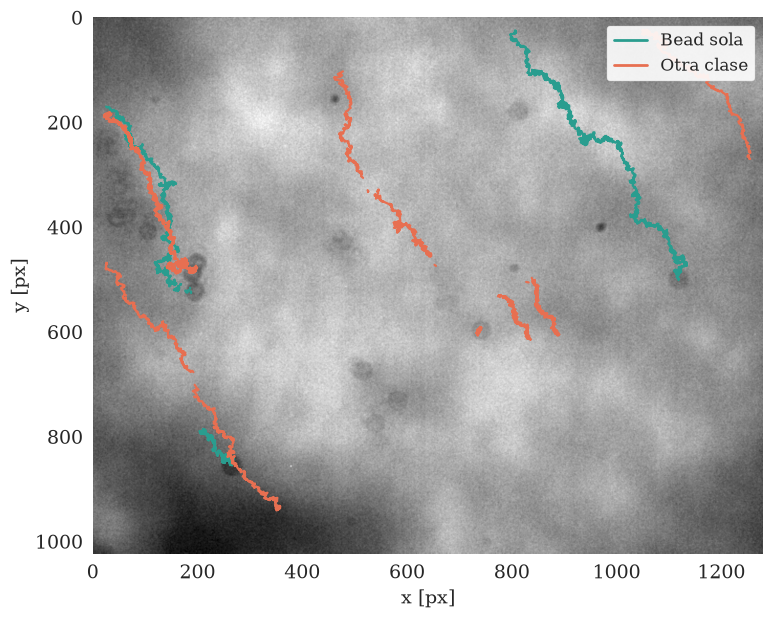

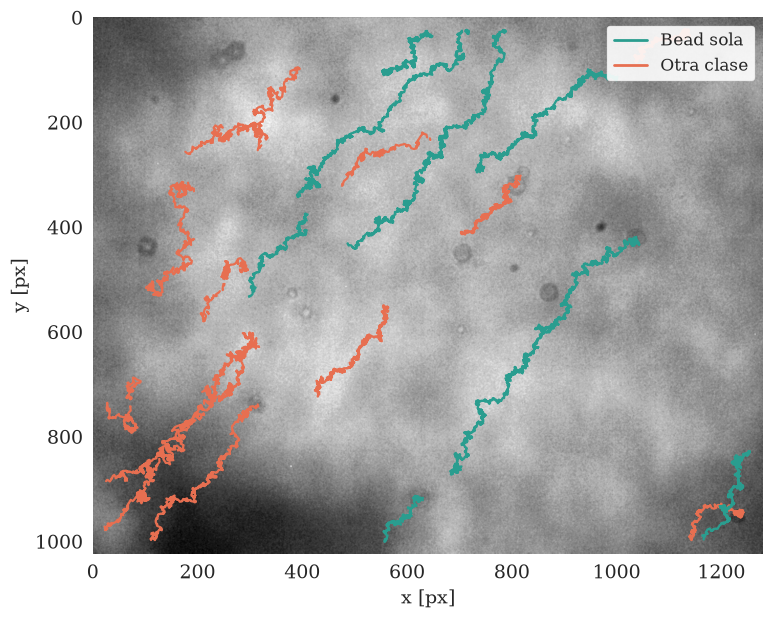

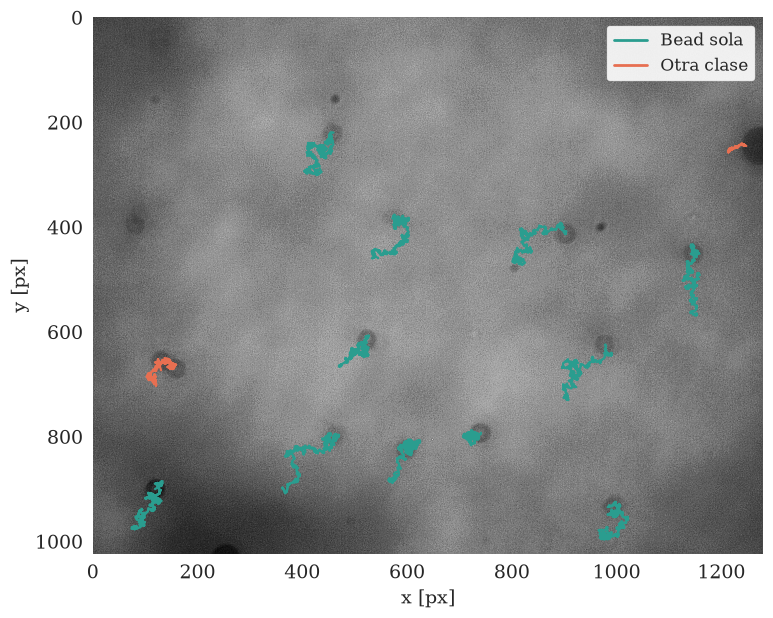

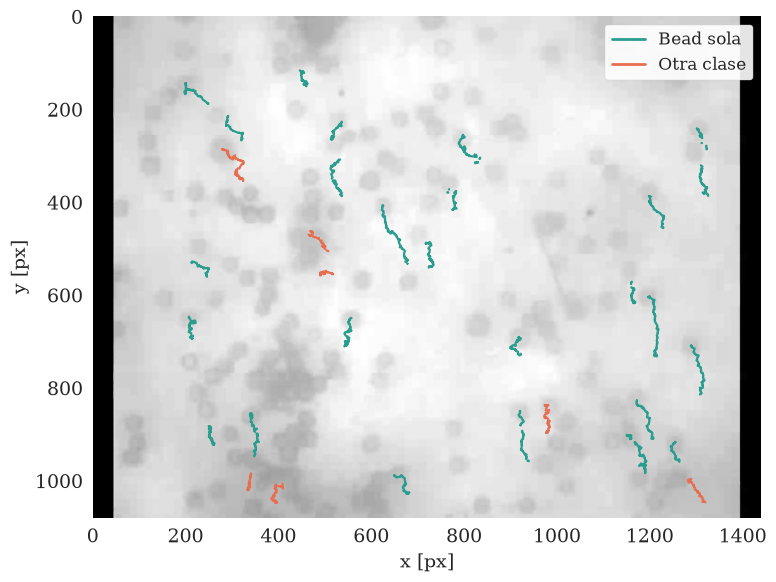

In [3]:
for nombre, M in MED.items():
    fig, ax = plt.subplots(figsize=(8, 6.4))
    img = M["datos"]["cuadro0"]
    img = img[..., :3].mean(-1) if img.ndim == 3 else img
    ax.imshow(img, cmap="gray", zorder=0)
    for k in range(len(M["ids"])):
        ax.plot(M["X"][:, k] / M["escala"], M["Y"][:, k] / M["escala"], "-", lw=1.6, zorder=2,
                color=SERIE1 if M["clase"][k] == "sola" else SERIE2)
    ax.plot([], [], "-", color=SERIE1, lw=2, label="Bead sola")
    ax.plot([], [], "-", color=SERIE2, lw=2, label="Otra clase")
    ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0)
    ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
    ax.legend(loc="upper right", fontsize=12, **LEYENDA)
    guardar(fig, "trayectorias_" + archivo(nombre))

radio aparente de las beads solas [µm]:
                   n  media  desvío    mín    máx
medición                                         
BROWNIANO 1        3  1.804   0.017  1.789  1.823
BROWNIANO 2        7  1.819   0.082  1.700  1.943
GROS BROWNIANO    11  1.907   0.093  1.772  2.060
CHICAS BROWNIANO  26  1.898   0.142  1.662  2.238
cociente CHICAS / nuestras en px del video: 1.105 (si la escala supuesta está bien y las beads son las mismas: 1080/1024 = 1.055)


,medición,partícula,clase,cuadros,R_ap [µm],err R_ap [µm],alfa,deriva [µm/s],D recta [µm²/s]
0,BROWNIANO 1,0,sola,757,1.823,0.008,0.788,0.123,0.049
1,BROWNIANO 1,1,sola,1842,1.789,0.063,1.075,0.185,0.059
2,BROWNIANO 1,2,sola,3122,1.800,0.014,1.045,0.174,0.058
3,BROWNIANO 1,3,confinada,647,1.824,0.008,0.339,NaN,NaN
4,BROWNIANO 1,6,agregado,3549,2.167,0.063,0.950,0.084,0.031
5,BROWNIANO 1,7,chica,684,1.242,0.067,0.993,0.449,0.121
6,BROWNIANO 1,24,fuera de foco,376,1.950,0.091,0.898,0.693,0.103
7,BROWNIANO 1,26,fuera de foco,450,1.673,0.127,1.167,0.713,0.097
8,BROWNIANO 1,27,fuera de foco,352,1.766,0.099,0.971,0.714,0.087
9,BROWNIANO 1,40,agregado,307,2.665,0.101,0.776,0.342,0.026


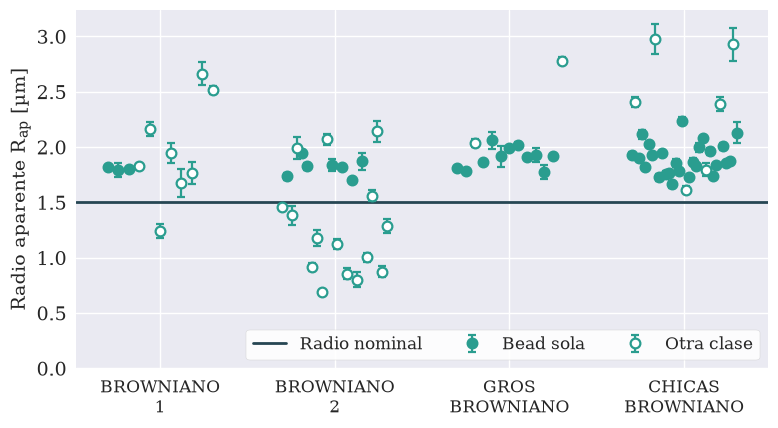

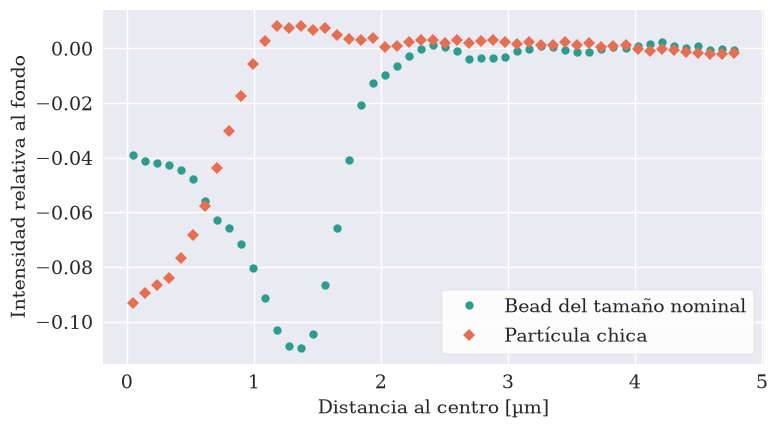

In [4]:
tabla_part = []
for nombre, M in MED.items():
    v = np.full(len(M["ids"]), np.nan); D = np.full(len(M["ids"]), np.nan)
    v[M["libres"]] = np.hypot(M["v"][:, 0], M["v"][:, 1]); D[M["libres"]] = M["D_ref"]
    tabla_part.append(pd.DataFrame({"medición": nombre, "partícula": M["ids"], "clase": M["clase"],
                                    "cuadros": np.isfinite(M["X"]).sum(0), "R_ap [µm]": M["Rap"], "err R_ap [µm]": M["eRap"],
                                    "alfa": M["alfa"], "deriva [µm/s]": v, "D recta [µm²/s]": D}))
tabla_part = pd.concat(tabla_part, ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (nombre, M) in enumerate(MED.items()):
    corr = np.linspace(-0.3, 0.3, len(M["ids"]))
    sola = M["clase"] == "sola"
    for sel, mfc, etiqueta in ((sola, SERIE1, "Bead sola"), (~sola, "white", "Otra clase")):
        ax.errorbar(i + corr[sel], M["Rap"][sel], M["eRap"][sel], fmt="o", color=SERIE1, mec=SERIE1, mfc=mfc,
                    label=etiqueta if i == 0 else None, **MARCA)
ax.axhline(R_NOMINAL, color=AJUSTE, lw=2, zorder=2, label="Radio nominal")
ax.set_xticks(range(len(MED)), [n.replace(" ", "\n") for n in MED], fontsize=12)
ax.set_ylabel(r"Radio aparente $R_{ap}$ [µm]")
ax.set_ylim(0, None)
ax.legend(loc="lower right", fontsize=12, ncol=3, **LEYENDA)
guardar(fig, "radios")

# el perfil radial de una bead del tamaño nominal y de una chica (BROWNIANO 2)
perf = pd.read_csv(os.path.join(RAIZ, "datos", "BROWNIANO 2", "perfiles.csv"))
fig, ax = plt.subplots(figsize=(8, 4.5))
for pid, color, fmt, etiqueta in ((22, SERIE1, "o", "Bead del tamaño nominal"), (14, SERIE2, "D", "Partícula chica")):
    ax.plot(perf.r_px * ESCALA, perf[str(pid)], fmt, color=color, ms=6, zorder=3, label=etiqueta)
ax.set_xlabel("Distancia al centro [µm]")
ax.set_ylabel("Intensidad relativa al fondo")
ax.legend(loc="lower right", **LEYENDA)
guardar(fig, "perfiles")

solas = tabla_part[tabla_part.clase == "sola"].groupby("medición", sort=False)["R_ap [µm]"]
print("radio aparente de las beads solas [µm]:")
print(pd.DataFrame({"n": solas.count(), "media": solas.mean(), "desvío": solas.std(), "mín": solas.min(), "máx": solas.max()}).round(3))
print("cociente CHICAS / nuestras en px del video: %.3f (si la escala supuesta está bien y las beads son las mismas: 1080/1024 = %.3f)"
      % (solas.mean()["CHICAS BROWNIANO"] / MED["CHICAS BROWNIANO"]["escala"] /
         (0.5 * (solas.mean()["BROWNIANO 1"] + solas.mean()["BROWNIANO 2"]) / ESCALA), 1080 / 1024))
tabla_part[tabla_part["medición"].isin(["BROWNIANO 1", "BROWNIANO 2"])].round(3)

## 3. Seis formas de sacar la deriva

Con una deriva de velocidad $v$, $\mathrm{MSD}(\tau) = 4D\tau + v^2\tau^2 + 4\sigma^2$: el MSD se curva hacia arriba y $D$ sale de más. Las formas que se comparan (`analizar_deriva` en `trayectorias.py`):

| | Método | Qué supone de la deriva | Qué le hace al browniano |
|---|---|---|---|
| (a) | **sin restar** | que no hay | nada |
| (b) | **deriva común**: se resta el promedio de los pasos de todas | que es la misma para todas en cada instante (puede cambiar en el tiempo) | el promedio incluye a la propia partícula: el MSD baja en $1 - 1/N$. Se corrige exacto si todas tienen el mismo $D$. Con pocas partículas a la vez, la deriva estimada es ruido |
| (c) | **recta por partícula**: a cada una se le resta su recta $x(t)$, $y(t)$ | que cada partícula va a velocidad constante (distinta entre partículas) | le saca al browniano su pendiente media: sesgo del orden de $\tau/T$ |
| (d) | **media móvil por partícula** (pasa-altos de ancho $W$) | que cambia más despacio que $W$ | saca todo lo más lento que $W$, también el browniano: sesgo del orden de $\tau/W$ |
| (e) | **pares**: MSD de la separación entre dos partículas, $4(D_1 + D_2)\tau$ | que es común (puede cambiar en el tiempo) | nada. Necesita partículas simultáneas; los pares no son independientes |
| (f) | **ajuste con deriva**: no se resta nada y se ajusta $4D\tau + v^2\tau^2 + 4\sigma^2$ | que cada partícula va a velocidad constante | nada. Usa los retardos largos, que son los más ruidosos |

En todos menos (f), $D$ sale del ajuste lineal de los primeros 4 retardos del MSD de cada partícula; se informa la media entre partículas y su error (desvío / $\sqrt{N}$). $\alpha$ es la pendiente log-log del MSD promedio en los 30 retardos.

### Validación con datos sintéticos

Antes de aplicarlos, se prueban con brownianos simulados con $D$ conocido (12 partículas, 600 cuadros a 15 cuadros/s, $D$ = 0.15 µm²/s, ruido de localización de 0.03 µm) a los que se les suma una deriva conocida:

- **común constante:** 0.36 µm/s para todas;
- **común que cambia:** un vaivén de 2 y 3 µm de amplitud con períodos de 15 y 25 s (hasta 0.8 µm/s);
- **distinta por partícula:** cada una con su velocidad constante (0.4 µm/s de desvío por eje).

Son derivas del tamaño de las medidas (0.1 a 1 µm/s).

D recuperado / D verdadero (media de 40 repeticiones; el error de la media es ~0.004 donde el método anda)
                     browniano puro  común constante  común que cambia  distinta por partícula  común que cambia + distinta por partícula
sin restar                    1.001            1.069             1.351                   1.165                                      1.517
deriva común                  1.002            0.997             1.001                   1.165                                      1.174
recta por partícula           0.994            0.992             1.338                   0.991                                      1.339
media móvil                   0.965            0.960             1.044                   0.962                                      1.047
pares                         1.002            0.997             1.001                   1.165                                      1.174
ajuste con deriva             1.002            0.995             

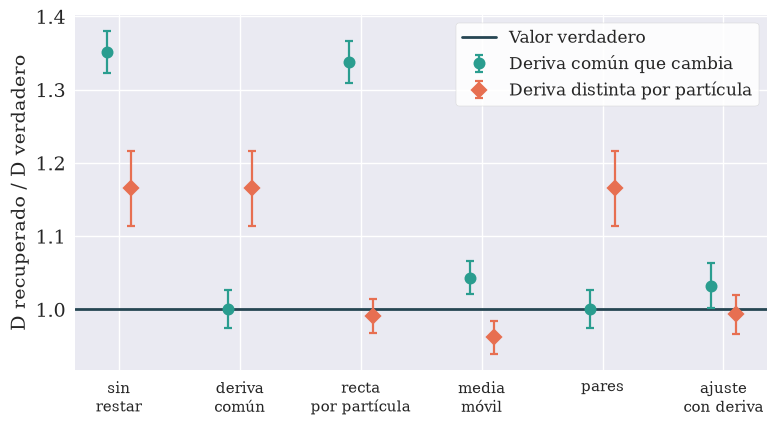

In [5]:
def sintetico(caso, n=600, nb=12, fps=15.0, D0=0.15, sigma=0.03):
    t = np.arange(n) / fps
    comun = v = None
    if caso == "común constante":
        comun = np.c_[0.3 * t, -0.2 * t]
    if "común que cambia" in caso:
        comun = np.c_[2.0 * np.sin(2 * np.pi * t / 15), 3.0 * np.cos(2 * np.pi * t / 25)]
    if "distinta por partícula" in caso:
        v = rng.normal(0, 0.4, (nb, 2))
    return (t, *simular(t, np.ones((n, nb), bool), D0, sigma=sigma, v=v, deriva_comun=comun, rng=rng)), D0


CASOS_SINT = ["browniano puro", "común constante", "común que cambia", "distinta por partícula",
              "común que cambia + distinta por partícula"]
val = {}
for caso in CASOS_SINT:
    res = {m: [] for m in METODOS_DERIVA}
    for _ in range(N_SIM):
        (t_, X_, Y_), D0 = sintetico(caso)
        for m in METODOS_DERIVA:
            r = analizar_deriva(t_, X_, Y_, m, ventana_s=10.0, max_lag=MAX_LAG, n_ajuste=N_AJUSTE)
            res[m].append((r["D"] / D0, r["alfa"]))
    val[caso] = {m: np.array(v) for m, v in res.items()}

print("D recuperado / D verdadero (media de %d repeticiones; el error de la media es ~0.004 donde el método anda)" % N_SIM)
print(pd.DataFrame({caso: {m: val[caso][m][:, 0].mean() for m in METODOS_DERIVA} for caso in CASOS_SINT}).round(3).to_string())
print("\nalfa (pendiente log-log del MSD promedio)")
print(pd.DataFrame({caso: {m: val[caso][m][:, 1].mean() for m in METODOS_DERIVA} for caso in CASOS_SINT}).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(METODOS_DERIVA))
for caso, color, fmt, corr, etiqueta in (("común que cambia", SERIE1, "o", -0.1, "Deriva común que cambia"),
                                         ("distinta por partícula", SERIE2, "D", 0.1, "Deriva distinta por partícula")):
    y = np.array([val[caso][m][:, 0].mean() for m in METODOS_DERIVA])
    e = np.array([val[caso][m][:, 0].std() for m in METODOS_DERIVA])
    ax.errorbar(x + corr, y, e, fmt=fmt, color=color, mfc=color, mec=color, label=etiqueta, **MARCA)
ax.axhline(1, color=AJUSTE, lw=2, zorder=2, label="Valor verdadero")
ax.set_xticks(x, [m.replace(" ", "\n", 1) for m in METODOS_DERIVA], fontsize=11)
ax.set_ylabel(r"$D$ recuperado / $D$ verdadero")
ax.legend(loc="upper right", fontsize=12, **LEYENDA)
guardar(fig, "validacion_sinteticos")

Lo que muestran los sintéticos:

- Con browniano puro todos devuelven $D$ dentro del 1 %, salvo la media móvil de 10 s, que se lleva 3.5 %.
- **Deriva común** y **pares** sacan cualquier deriva común, aunque cambie en el tiempo (1.00), y no sacan nada de la que es distinta en cada partícula (1.17, igual que sin restar).
- **Recta por partícula** y **ajuste con deriva** sacan la deriva constante de cada partícula (0.99). Si la deriva cambia en el tiempo, la recta no saca nada (1.34); el ajuste con deriva aguanta (1.03) porque en 2 s el vaivén se parece a una velocidad constante.
- La **media móvil** y el **ajuste con deriva** son los únicos que quedan a menos de 5 % en todos los casos. A la media móvil de 10 s se le escapa parte de un vaivén de 15 s de período: la ventana tiene que ser más corta que lo que tarda en cambiar la deriva, y cuanto más corta, más browniano se lleva. Ese sesgo se puede medir y corregir (sigue).
- El error que informa cada método (desvío entre partículas / $\sqrt{N}$) no avisa del sesgo: hay que saber qué deriva hay.

### Cuánto browniano se lleva cada método: simulación gemela

El sesgo depende de la duración de cada trayectoria, de sus huecos y de cuántas partículas hay a la vez. Para cada medición se simula un browniano **puro** con los mismos tiempos, los mismos huecos, el $D$ y el ruido de localización de cada partícula (los del método de la recta), y se le aplican los seis métodos. El cociente $D$ recuperado / $D$ verdadero es el **factor** de cada método en esa medición; en la comparación de la sección 4 cada $D$ se divide por su factor.

La tabla del medio es el factor calculado solo sobre las beads solas. Importa en la deriva común cuando hay partículas de $D$ muy distinto: el promedio les pasa a las lentas parte del browniano de las rápidas.

La última tabla es la misma simulación **con la deriva medida** sumada (la velocidad de cada partícula y el vaivén común suavizado a 5 s): dice qué métodos recuperan $D$ con una deriva como la de cada medición. Ese vaivén se estima promediando las partículas, así que trae también el browniano de ellas dividido por $N$. Con las 2.3 partículas a la vez de BROWNIANO 1 eso no es despreciable: ahí la simulación suma una deriva que en parte no existe y sus números son una cota por arriba.

In [6]:
def gemela(M, casos, n_rep=N_SIM, con_deriva=False):
    """Simulación gemela de la medición M. casos: lista de (etiqueta, método, kwargs de analizar_deriva).
    Devuelve {etiqueta: (D recuperado / D verdadero, su error)} para todas las libres, lo mismo solo para las
    beads solas y, por partícula, la dispersión relativa de D con el método de la recta (el error estadístico
    de un D individual)."""
    t, mask, D0, s = M["t"], np.isfinite(M["Xl"]), M["D_ref"], M["solas"]
    coc, coc_s, por_part = {e: [] for e, _, _ in casos}, {e: [] for e, _, _ in casos}, []
    for _ in range(n_rep):
        Xg, Yg = simular(t, mask, D0, sigma=M["sigma_ref"], v=M["v"] if con_deriva else None,
                         deriva_comun=M["vaiven"] if con_deriva else None, rng=rng)
        for e, metodo, kw in casos:
            r = analizar_deriva(t, Xg, Yg, metodo, max_lag=MAX_LAG, n_ajuste=N_AJUSTE, solape_min=M["largo_min"], **kw)
            if r.get("D_es_del_conjunto"):               # pares sin solución por partícula: D del conjunto de pares
                p, w = r["pares"], r["pesos_pares"]
                coc[e].append(r["D"] / (np.sum(w * (D0[p[:, 0]] + D0[p[:, 1]]) / 2) / np.sum(w)))
            else:
                ok = np.isfinite(r["D_i"])
                coc[e].append(np.mean(r["D_i"][ok]) / np.mean(D0[ok]) if ok.any() else np.nan)
            coc_s[e].append(np.mean(r["D_i"][s]) / np.mean(D0[s]))          # NaN si a alguna sola le falta D
            if metodo == "recta por partícula":
                por_part.append(r["D_i"] / D0)
    media = lambda d: {e: (np.nanmean(c), np.nanstd(c, ddof=1) / np.sqrt(len(c))) for e, c in d.items()}
    return media(coc), media(coc_s), np.std(por_part, axis=0) if por_part else None


FACTOR, FACTOR_SOLAS, FACTOR_DERIVA = {}, {}, {}
for nombre, M in MED.items():
    casos = [(m, m, dict(ventana_s=M["ventana"]) if m == "media móvil" else {}) for m in METODOS_DERIVA]
    FACTOR[nombre], FACTOR_SOLAS[nombre], M["err_rel_D"] = gemela(M, casos)
    FACTOR_DERIVA[nombre], _, _ = gemela(M, casos, con_deriva=True)

print("browniano puro: D recuperado / D verdadero (factor de cada método)")
print(pd.DataFrame({n: {m: "%.3f ± %.3f" % FACTOR[n][m] for m in METODOS_DERIVA} for n in MED}).to_string())
print("\nbrowniano puro, solo las beads solas")
print(pd.DataFrame({n: {m: "%.3f ± %.3f" % FACTOR_SOLAS[n][m] for m in METODOS_DERIVA} for n in MED}).to_string())
print("\ncon la deriva medida sumada: D recuperado / D verdadero")
print(pd.DataFrame({n: {m: "%.3f ± %.3f" % FACTOR_DERIVA[n][m] for m in METODOS_DERIVA} for n in MED}).to_string())

browniano puro: D recuperado / D verdadero (factor de cada método)
                       BROWNIANO 1    BROWNIANO 2 GROS BROWNIANO CHICAS BROWNIANO
sin restar           0.999 ± 0.005  1.005 ± 0.004  1.000 ± 0.004    1.003 ± 0.005
deriva común         1.125 ± 0.013  0.980 ± 0.004  1.004 ± 0.004    1.003 ± 0.005
recta por partícula  0.992 ± 0.005  0.992 ± 0.004  0.993 ± 0.004    0.974 ± 0.005
media móvil          0.947 ± 0.005  0.948 ± 0.004  0.964 ± 0.004    0.930 ± 0.005
pares                0.992 ± 0.004  1.014 ± 0.005  1.000 ± 0.004    1.001 ± 0.005
ajuste con deriva    1.006 ± 0.006  1.003 ± 0.005  1.006 ± 0.006    1.002 ± 0.006

browniano puro, solo las beads solas
                       BROWNIANO 1    BROWNIANO 2 GROS BROWNIANO CHICAS BROWNIANO
sin restar           0.991 ± 0.004  0.993 ± 0.005  0.999 ± 0.004    1.005 ± 0.005
deriva común         0.988 ± 0.006  1.069 ± 0.006  0.997 ± 0.004    1.006 ± 0.006
recta por partícula  0.989 ± 0.004  0.988 ± 0.005  0.992 ± 0.004    0.974 ±

### La ventana de la media móvil

Con una ventana $W$ chica se saca bien cualquier deriva pero se pierde mucho browniano; con una grande se pierde poco pero pasa la deriva lenta. Para cada medición se barre $W$, se calcula $D$ (media de las partículas libres) y se lo corrige con el factor de la simulación gemela para esa misma ventana. Si lo único que hay es browniano más una deriva lenta, el $D$ corregido no tiene que depender de $W$.

BROWNIANO 1
 W      D    err  factor  D_corr   alfa
 1 0.0315 0.0054  0.4854  0.0650 0.0146
 2 0.0492 0.0073  0.7437  0.0661 0.1512
 3 0.0550 0.0079  0.8334  0.0660 0.2921
 5 0.0587 0.0090  0.8992  0.0653 0.5509
 8 0.0615 0.0094  0.9372  0.0656 0.7262
12 0.0631 0.0097  0.9560  0.0660 0.7976
20 0.0645 0.0098  0.9715  0.0664 0.8486
40 0.0660 0.0101  0.9849  0.0670 0.8831


BROWNIANO 2
 W      D    err  factor  D_corr   alfa
 1 0.0843 0.0102  0.4878  0.1728 0.0342
 2 0.1329 0.0169  0.7413  0.1793 0.1907
 3 0.1498 0.0194  0.8312  0.1802 0.3443
 5 0.1587 0.0209  0.9017  0.1760 0.6140
 8 0.1669 0.0222  0.9452  0.1765 0.7910
12 0.1707 0.0226  0.9647  0.1770 0.8600
20 0.1741 0.0230  0.9835  0.1770 0.8955
40 0.1786 0.0237  0.9977  0.1790 0.9430


GROS BROWNIANO
 W      D    err  factor  D_corr   alfa
 1 0.0953 0.0081  0.6312  0.1510 0.1411
 2 0.1267 0.0108  0.8277  0.1531 0.4307
 3 0.1361 0.0114  0.8827  0.1542 0.6546
 5 0.1452 0.0120  0.9297  0.1561 0.8753
 8 0.1481 0.0120  0.9570  0.1547 0.9518
12 0.1515 0.0125  0.9704  0.1562 1.0051
20 0.1532 0.0127  0.9841  0.1557 1.0307
40 0.1550 0.0129  0.9939  0.1560 1.0503


CHICAS BROWNIANO
   W      D    err  factor  D_corr   alfa
 0.5 0.0402 0.0023  0.4518  0.0890 0.0359
 1.0 0.0721 0.0033  0.7330  0.0983 0.2500
 1.5 0.0799 0.0039  0.8199  0.0974 0.4402
 2.0 0.0865 0.0043  0.8658  0.0999 0.6202
 3.0 0.0942 0.0049  0.9094  0.1036 0.8177
 4.0 0.0962 0.0048  0.9297  0.1035 0.8907
 6.0 0.0999 0.0056  0.9511  0.1050 0.9653
10.0 0.1017 0.0052  0.9710  0.1048 1.0268


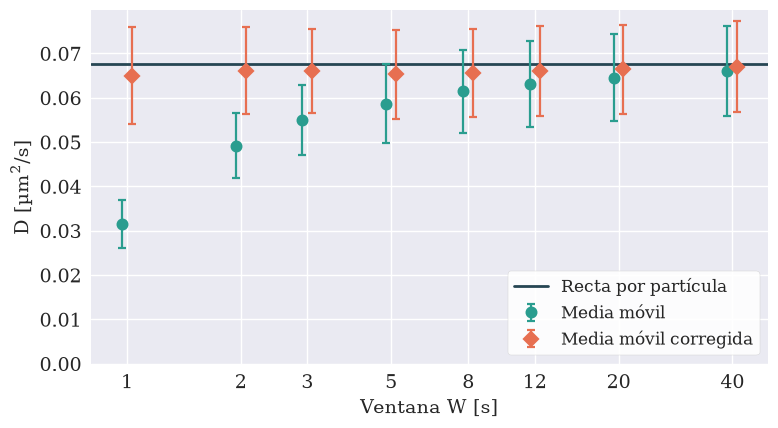

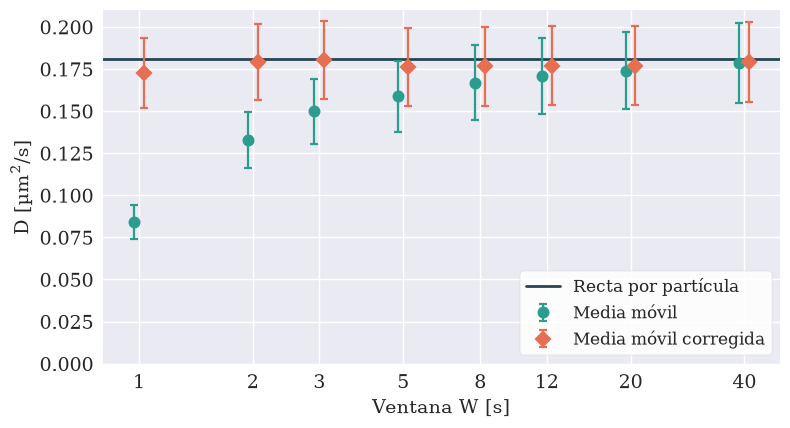

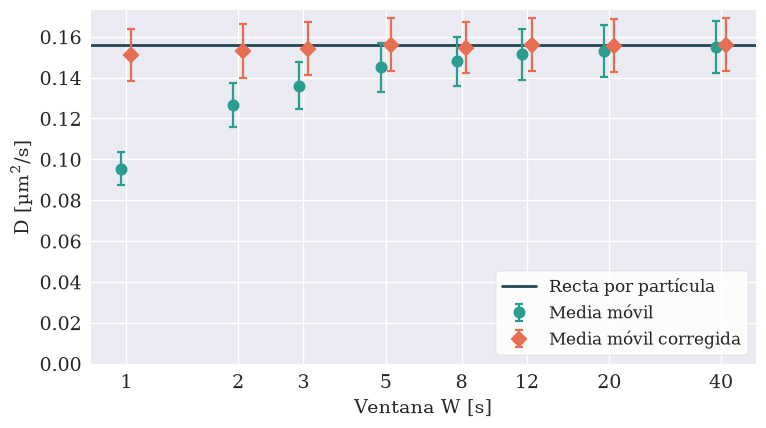

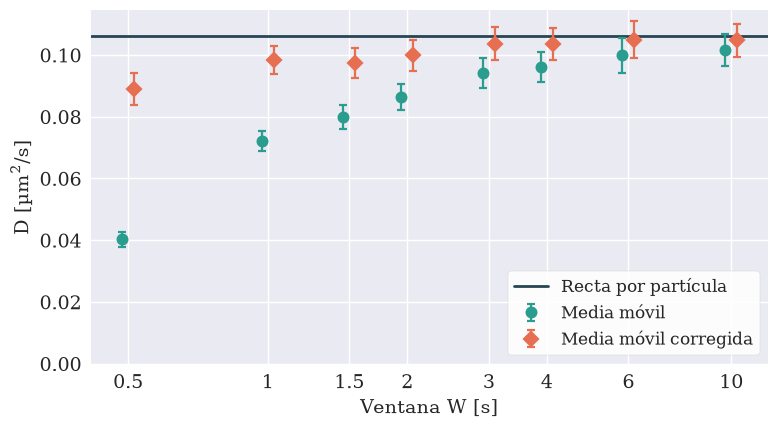

In [7]:
barrido = {}
for nombre, M in MED.items():
    Ws = [w for w in M["ventanas"]]
    f, _, _ = gemela(M, [(w, "media móvil", dict(ventana_s=w)) for w in Ws], n_rep=N_SIM // 2)
    filas = []
    for w in Ws:
        r = analizar_deriva(M["t"], M["Xl"], M["Yl"], "media móvil", ventana_s=w, max_lag=MAX_LAG, n_ajuste=N_AJUSTE)
        filas.append(dict(W=w, D=r["D"], err=r["err_D"], factor=f[w][0], D_corr=r["D"] / f[w][0], alfa=r["alfa"]))
    barrido[nombre] = b = pd.DataFrame(filas)
    recta = analizar_deriva(M["t"], M["Xl"], M["Yl"], "recta por partícula", max_lag=MAX_LAG, n_ajuste=N_AJUSTE,
                            corregir=FACTOR[nombre]["recta por partícula"][0])

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.errorbar(b.W * 0.97, b.D, b.err, fmt="o", color=SERIE1, mfc=SERIE1, mec=SERIE1, label="Media móvil", **MARCA)
    ax.errorbar(b.W * 1.03, b.D_corr, b.err / b.factor, fmt="D", color=SERIE2, mfc=SERIE2, mec=SERIE2,
                label="Media móvil corregida", **MARCA)
    ax.axhline(recta["D"], color=AJUSTE, lw=2, zorder=2, label="Recta por partícula")
    ax.set_xscale("log")
    ax.set_xticks(b.W, ["%g" % w for w in b.W])
    ax.minorticks_off()
    ax.set_xlabel(r"Ventana $W$ [s]")
    ax.set_ylabel(r"$D$ [µm$^2$/s]")
    ax.set_ylim(0, None)
    ax.legend(loc="lower right", fontsize=12, **LEYENDA)
    guardar(fig, "ventana_" + archivo(nombre))
    print(nombre)
    print(b.round(4).to_string(index=False))

## 4. Los seis métodos sobre las cuatro mediciones

Cada método se aplica a las partículas libres de cada medición. $D$ ya está dividido por el factor de la simulación gemela. Las columnas:

- **alfa:** pendiente log-log del MSD promedio (1 = difusión; más de 1 = queda deriva). En (f) es la del MSD menos el término $v^2\tau^2$ ajustado. El ruido de localización la baja y la exposición la sube, sin que haya deriva.
- **D libres / D solas:** media de $D$ entre las partículas libres, y entre las beads solas (las que se comparan con Stokes–Einstein), con su error.
- **media/σ:** media del paso de un cuadro dividida por su desvío (promedio cuadrático entre partículas): la deriva que queda.
- **curtosis:** en exceso, de los pasos de un cuadro normalizados por partícula (0 = gaussiana).
- **corr:** correlación entre un paso y el siguiente.

La tabla completa se guarda en `datos/BROWNIANO comparación/resumen.csv`.

In [8]:
RES, filas = {}, []
for nombre, M in MED.items():
    for m in METODOS_DERIVA:
        r = analizar_deriva(M["t"], M["Xl"], M["Yl"], m, ventana_s=M["ventana"], max_lag=MAX_LAG, n_ajuste=N_AJUSTE,
                            solape_min=M["largo_min"], corregir=FACTOR[nombre][m][0])
        RES[nombre, m] = r
        fs_ = FACTOR_SOLAS[nombre][m][0]                     # NaN si el método no da D para cada bead sola
        r["D_i_solas"] = Ds = r["D_i"][M["solas"]] * FACTOR[nombre][m][0] / fs_ if np.isfinite(fs_) else np.zeros(0)
        filas.append({"medicion": nombre, "metodo": m, "ventana_s": M["ventana"] if m == "media móvil" else np.nan,
                      "n_libres": r["n"], "alfa": r["alfa"], "err_alfa": r["err_alfa"],
                      "D_libres_um2_s": r["D"], "err_D_libres_um2_s": r["err_D"], "D_conjunto_um2_s": r["D_conjunto"],
                      "n_solas": len(Ds), "D_solas_um2_s": Ds.mean() if len(Ds) else np.nan,
                      "err_D_solas_um2_s": Ds.std(ddof=1) / np.sqrt(len(Ds)) if len(Ds) > 1 else np.nan,
                      "factor_gemela": FACTOR[nombre][m][0], "err_factor_gemela": FACTOR[nombre][m][1],
                      "factor_gemela_solas": FACTOR_SOLAS[nombre][m][0],
                      "factor_gemela_con_deriva": FACTOR_DERIVA[nombre][m][0],
                      "ordenada_um2": r["ordenada"], "media_sobre_sigma": r["media_sobre_sigma"],
                      "curtosis": r["curtosis"], "err_curtosis": r["err_curtosis"],
                      "correlacion_pasos": r["corr"], "err_correlacion_pasos": r["err_corr"],
                      "anisotropia": r["anisotropia"], "err_anisotropia": r["err_anisotropia"]})
resumen = pd.DataFrame(filas)
resumen.to_csv(os.path.join(SALIDA, "resumen.csv"), index=False, float_format="%.5g")

ver = resumen[["medicion", "metodo", "n_libres", "alfa", "err_alfa", "D_libres_um2_s", "err_D_libres_um2_s", "n_solas",
               "D_solas_um2_s", "err_D_solas_um2_s", "media_sobre_sigma", "curtosis", "correlacion_pasos"]]
ver.columns = ["medición", "método", "n", "alfa", "±", "D libres", "±", "n solas", "D solas", "±", "media/σ", "curtosis", "corr"]
ver.round(4)

,medición,método,n,alfa,±,D libres,±,n solas,D solas,±,media/σ,curtosis,corr
0,BROWNIANO 1,sin restar,10,1.1605,0.0565,0.0918,0.0172,3,0.0592,0.0041,0.1765,0.6325,-0.1383
1,BROWNIANO 1,deriva común,10,1.0365,0.0291,0.0667,0.0094,3,0.0544,0.0044,0.0828,0.4781,-0.1411
2,BROWNIANO 1,recta por partícula,10,0.9349,0.0381,0.0677,0.0104,3,0.0562,0.0033,0.0128,0.6325,-0.1383
3,BROWNIANO 1,media móvil,10,0.7722,0.0474,0.0656,0.0100,3,0.0550,0.0027,0.0062,0.6399,-0.1493
4,BROWNIANO 1,pares,10,1.0361,0.0239,0.0601,0.0112,0,NaN,NaN,0.0975,0.2874,-0.1175
5,BROWNIANO 1,ajuste con deriva,10,0.9035,0.0285,0.0658,0.0098,3,0.0545,0.0016,0.1765,0.6325,-0.1383
6,BROWNIANO 2,sin restar,22,1.1462,0.0185,0.2030,0.0270,7,0.0880,0.0068,0.1614,0.3858,-0.0448
7,BROWNIANO 2,deriva común,22,1.0111,0.0153,0.1824,0.0222,7,0.0810,0.0044,0.0812,0.3056,-0.0418
8,BROWNIANO 2,recta por partícula,22,0.9578,0.0194,0.1808,0.0239,7,0.0791,0.0055,0.0292,0.3858,-0.0448
9,BROWNIANO 2,media móvil,22,0.8363,0.0184,0.1793,0.0240,7,0.0785,0.0054,0.0130,0.3915,-0.0537


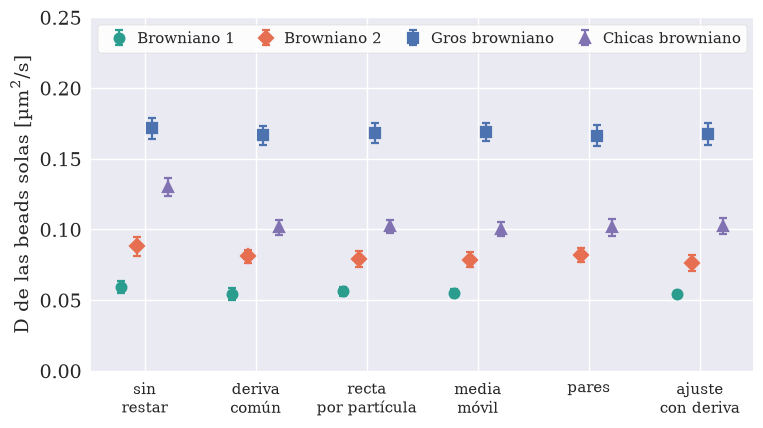

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(METODOS_DERIVA))
for (nombre, M), color, fmt, corr in zip(MED.items(), (SERIE1, SERIE2, SERIE3, SERIE4), ("o", "D", "s", "^"), (-0.21, -0.07, 0.07, 0.21)):
    d = resumen[resumen.medicion == nombre]
    ax.errorbar(x + corr, d.D_solas_um2_s, d.err_D_solas_um2_s, fmt=fmt, color=color, mfc=color, mec=color,
                label=nombre.capitalize(), **MARCA)
ax.set_xticks(x, [m.replace(" ", "\n", 1) for m in METODOS_DERIVA], fontsize=11)
ax.set_ylabel(r"$D$ de las beads solas [µm$^2$/s]")
ax.set_ylim(0, 0.25)
ax.legend(loc="upper center", fontsize=11, ncol=4, columnspacing=1.0, handletextpad=0.2, **LEYENDA)
guardar(fig, "D_por_metodo")

### Qué método conviene en cada medición

La regla que sale de los sintéticos y de las gemelas: si hay muchas partículas a la vez y son todas iguales, **deriva común** o **pares** (no pierden browniano y sacan una deriva que cambia en el tiempo); si cada partícula deriva distinto, **recta por partícula**, con la **media móvil corregida** como control: si su $D$ no depende de la ventana, la recta alcanza.

- **BROWNIANO 1: recta por partícula.** La deriva no es común: va de 0.08 a 0.71 µm/s según la partícula (las desenfocadas, que están a otra altura, van cuatro veces más rápido que las beads en foco) y hay solo 2.3 partículas a la vez. La deriva común deja $\alpha$ = 1.04 y, hecha con dos o tres partículas de $D$ distinto, tiene un factor de 1.12 en la gemela; con pares no se puede despejar el $D$ de cada partícula. La recta, la media móvil corregida y el ajuste con deriva dan lo mismo para las beads solas (0.055 a 0.056 µm²/s). La media móvil corregida da 0.065 a 0.067 µm²/s (todas las libres) con ventanas de 1 a 40 s: no hay una deriva variable de más de 3 % que la recta se esté perdiendo.
- **BROWNIANO 2: recta por partícula**, con pares como control. La deriva es parecida para casi todas las beads del tamaño nominal (0.24 a 0.31 µm/s; una va a 0.08) pero las chicas van más rápido (hasta 1 µm/s). Como hay partículas con $D$ cinco veces distinto, la deriva común les suma a las beads grandes parte del browniano de las chicas (factor 1.07 para las solas). Corregidos, los cinco métodos dan entre 0.076 y 0.082 µm²/s.
- **GROS: cualquiera; se usa la recta.** Hay 11.5 partículas a la vez durante todo el video y la deriva es chica (0.05 a 0.34 µm/s): sin restar nada $D$ sale solo 2 % de más. Los cinco métodos dan entre 0.166 y 0.169 µm²/s.
- **CHICAS: recta por partícula.** Es donde más pesa la deriva (0.5 a 1.2 µm/s): sin restar, $D$ sale 27 % de más. Con 20 partículas a la vez la deriva común también anda (0.101). Las trayectorias son cortas (4.5 a 10 s) y la recta se lleva 2.6 % del browniano (corregido). La media móvil corregida **sí** depende de la ventana (0.089 con 0.5 s, 0.105 con 6 s o más): a tiempos cortos el movimiento medido no es un browniano limpio (sección 5).

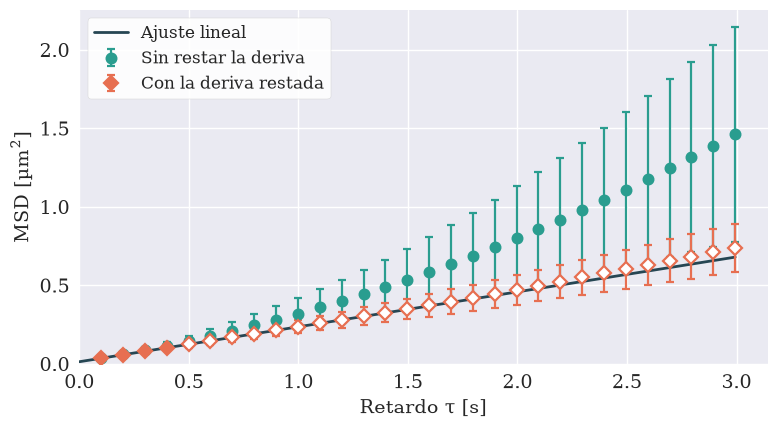

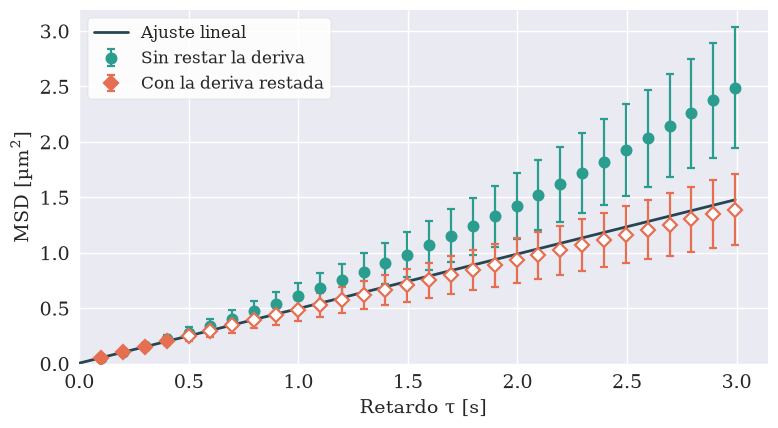

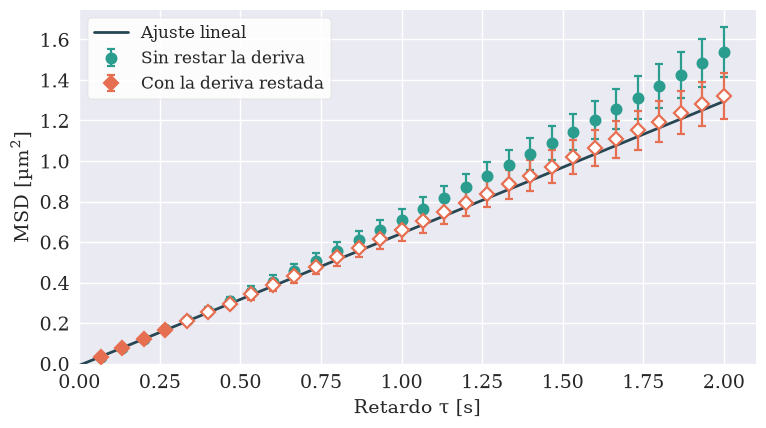

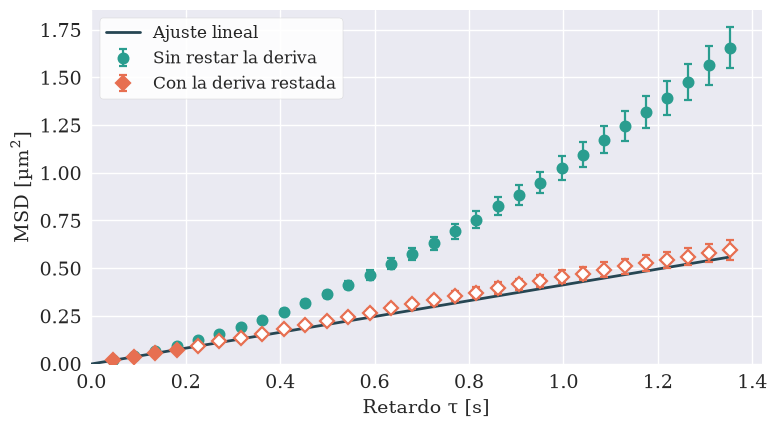

In [10]:
RECOMENDADO = {"BROWNIANO 1": "recta por partícula", "BROWNIANO 2": "recta por partícula",
               "GROS BROWNIANO": "recta por partícula", "CHICAS BROWNIANO": "recta por partícula"}
VALIDOS = {"BROWNIANO 1": ["recta por partícula", "media móvil", "ajuste con deriva"],
           "BROWNIANO 2": ["recta por partícula", "media móvil", "ajuste con deriva", "deriva común", "pares"],
           "GROS BROWNIANO": ["recta por partícula", "media móvil", "ajuste con deriva", "deriva común", "pares"],
           "CHICAS BROWNIANO": ["recta por partícula", "media móvil", "ajuste con deriva", "deriva común"]}

for nombre, M in MED.items():
    a, b = RES[nombre, "sin restar"], RES[nombre, RECOMENDADO[nombre]]
    aj = libre.ajustar_msd(b["tau"], b["msd"], 0.0, n_puntos=N_AJUSTE)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.errorbar(a["tau"], a["msd"], a["err_msd"], fmt="o", color=SERIE1, mfc=SERIE1, mec=SERIE1, label="Sin restar la deriva", **MARCA)
    ax.errorbar(b["tau"][:N_AJUSTE], b["msd"][:N_AJUSTE], b["err_msd"][:N_AJUSTE], fmt="D", color=SERIE2, mfc=SERIE2,
                mec=SERIE2, label="Con la deriva restada", **MARCA)
    ax.errorbar(b["tau"][N_AJUSTE:], b["msd"][N_AJUSTE:], b["err_msd"][N_AJUSTE:], fmt="D", color=SERIE2, mfc="white", mec=SERIE2, **MARCA)
    tt = np.linspace(0, b["tau"][-1], 50)
    ax.plot(tt, aj["pendiente"] * tt + aj["ordenada"], color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal")
    ax.set_xlabel(r"Retardo $\tau$ [s]")
    ax.set_ylabel(r"MSD [µm$^2$]")
    ax.set_xlim(0, None); ax.set_ylim(0, None)
    ax.legend(loc="upper left", fontsize=12, **LEYENDA)
    guardar(fig, "msd_" + archivo(nombre))

## 5. ¿Es browniano?

Con el método recomendado, las cuatro pruebas de siempre sobre las partículas libres:

1. **MSD lineal:** $\alpha$ cerca de 1, y cuánto se aparta el MSD medido de la recta (ajustada en los primeros 4 retardos) en el retardo más largo.
2. **Pasos gaussianos:** curtosis en exceso de los pasos de un cuadro, normalizados con la $\sigma$ de toda la trayectoria y con la $\sigma$ local (la de los 101 pasos de alrededor; 51 en CHICAS). Si la primera es alta y la segunda no, el tamaño del paso cambia a lo largo de la trayectoria pero cada paso es gaussiano.
3. **Isotropía:** $\sigma_y/\sigma_x$ de los pasos, media entre partículas.
4. **Pasos independientes:** correlación entre un paso y el siguiente. La ordenada $a$ del MSD dice cuánto se espera: $r = -a/(2(a + 4D\tau_1))$. Ruido de localización ($a > 0$) da correlación negativa; una exposición larga ($a < 0$), positiva. No es una prueba independiente del MSD.

In [11]:
def z_local(t, Xs, Ys, ventana):
    """Pasos de un cuadro divididos por la sigma local (la de `ventana` pasos alrededor), todas las partículas."""
    z = []
    for dx, dy in pasos_por_particula(t, Xs, Ys):
        for d in (dx, dy):
            if len(d) >= ventana:
                s = pd.Series(d).rolling(ventana, center=True, min_periods=ventana // 3).std().values
                z.append((d - d.mean()) / s)
    z = np.concatenate(z)
    return z[np.isfinite(z)]


def z_trayectoria(t, Xs, Ys):
    return np.concatenate([np.r_[(dx - dx.mean()) / dx.std(), (dy - dy.mean()) / dy.std()]
                           for dx, dy in pasos_por_particula(t, Xs, Ys) if len(dx) >= 20])


filas, Z = [], {}
for nombre, M in MED.items():
    r = RES[nombre, RECOMENDADO[nombre]]
    aj = libre.ajustar_msd(r["tau"], r["msd"], 0.0, n_puntos=N_AJUSTE)
    recta_fin = aj["pendiente"] * r["tau"][-1] + aj["ordenada"]
    Z[nombre] = z_trayectoria(M["t"], r["Xs"], r["Ys"])
    zl = z_local(M["t"], r["Xs"], r["Ys"], 51 if nombre == "CHICAS BROWNIANO" else 101)
    filas.append({"medición": nombre, "n": r["n"], "alfa": "%.2f ± %.2f" % (r["alfa"], r["err_alfa"]),
                  "MSD vs recta al final [%]": "%+.0f" % (100 * (r["msd"][-1] / recta_fin - 1)),
                  "error del MSD al final [%]": "%.0f" % (100 * r["err_msd"][-1] / r["msd"][-1]),
                  "curtosis (σ trayectoria)": "%.2f ± %.2f" % (r["curtosis"], r["err_curtosis"]),
                  "curtosis (σ local)": "%.2f ± %.2f" % (stats.kurtosis(zl), np.sqrt(24 / len(zl))),
                  "|z| > 3 [%]": "%.2f" % (100 * np.mean(np.abs(Z[nombre]) > 3)),
                  "σ robusta / σ": "%.2f" % (1.4826 * np.median(np.abs(Z[nombre] - np.median(Z[nombre])))),
                  "σy/σx": "%.2f ± %.2f" % (r["anisotropia"], r["err_anisotropia"]),
                  "corr medida": "%.3f ± %.3f" % (r["corr"], r["err_corr"]),
                  "corr esperada": "%.3f" % (-aj["ordenada"] / (2 * (aj["ordenada"] + aj["pendiente"] * r["tau"][0]))),
                  "ordenada [µm²]": "%.4f" % aj["ordenada"], "σ de localización [nm]": "%.0f" % (1e3 * aj["sigma"]),
                  # si la ordenada es negativa y fuera solo exposición: MSD = 4D(τ − W/3)
                  "exposición equivalente / período": "%.2f" % (-3 * aj["ordenada"] / aj["pendiente"] / M["dt"]) if aj["ordenada"] < 0 else "-"})
print("gaussiana: curtosis 0, |z| > 3 en 0.27 % de los pasos, σ robusta (1.4826 × desvío absoluto mediano) / σ = 1")
chequeos = pd.DataFrame(filas)
chequeos.set_index("medición").T

gaussiana: curtosis 0, |z| > 3 en 0.27 % de los pasos, σ robusta (1.4826 × desvío absoluto mediano) / σ = 1


medición,BROWNIANO 1,BROWNIANO 2,GROS BROWNIANO,CHICAS BROWNIANO
n,10,22,13,30
alfa,0.93 ± 0.04,0.96 ± 0.02,1.06 ± 0.02,1.05 ± 0.02
MSD vs recta al final [%],+9,-6,+2,+7
error del MSD al final [%],21,23,9,8
curtosis (σ trayectoria),0.63 ± 0.03,0.39 ± 0.03,0.32 ± 0.04,7.90 ± 0.05
curtosis (σ local),0.02 ± 0.03,0.01 ± 0.03,0.16 ± 0.04,5.63 ± 0.05
|z| > 3 [%],0.61,0.49,0.46,2.46
σ robusta / σ,0.94,0.96,0.97,0.34
σy/σx,0.97 ± 0.03,0.99 ± 0.02,1.03 ± 0.03,1.17 ± 0.04
corr medida,-0.138 ± 0.013,-0.045 ± 0.012,0.131 ± 0.017,0.037 ± 0.023


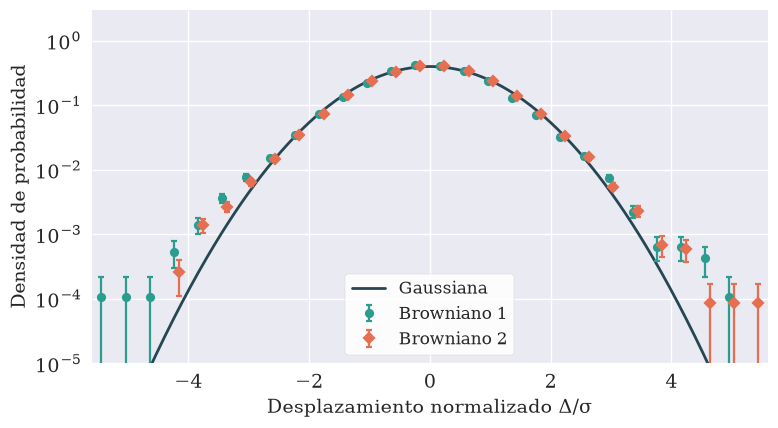

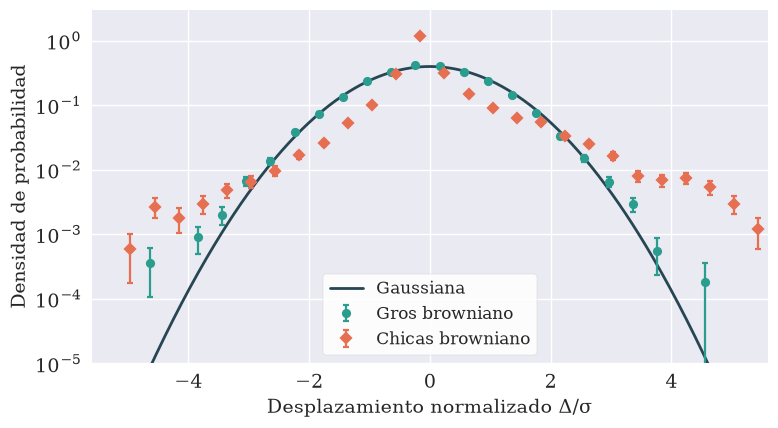

In [12]:
def densidad(z, bordes):
    n, _ = np.histogram(z, bordes)
    ancho = np.diff(bordes)
    ok = n > 0
    return (0.5 * (bordes[1:] + bordes[:-1]))[ok], (n / (len(z) * ancho))[ok], (np.sqrt(n) / (len(z) * ancho))[ok]


u_ = np.linspace(-5.6, 5.6, 400)
bordes = np.arange(-5.6, 5.61, 0.4)
for nombres, salida in ((("BROWNIANO 1", "BROWNIANO 2"), "histograma_nuestras"), (("GROS BROWNIANO", "CHICAS BROWNIANO"), "histograma_otros")):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for nombre, color, fmt, corr in zip(nombres, (SERIE1, SERIE2), ("o", "D"), (-0.04, 0.04)):
        cx, dens, e = densidad(Z[nombre], bordes)
        ax.errorbar(cx + corr, dens, e, fmt=fmt, color=color, mfc=color, mec=color, label=nombre.capitalize(),
                    **dict(MARCA, ms=5, capsize=2))
    ax.plot(u_, np.exp(-u_ ** 2 / 2) / np.sqrt(2 * np.pi), color=AJUSTE, lw=2, zorder=2, label="Gaussiana")
    ax.set_yscale("log")
    ax.set_xlabel(r"Desplazamiento normalizado $\Delta/\sigma$")
    ax.set_ylabel("Densidad de probabilidad")
    ax.set_xlim(-5.6, 5.6); ax.set_ylim(1e-5, 3)
    ax.legend(loc="lower center", fontsize=12, **LEYENDA)
    guardar(fig, salida)

## 6. Resultado físico: $D$ y Stokes–Einstein

$D$ de cada medición es la media de las **beads solas** con el método recomendado. Las incertezas, por separado:

- **estadística:** desvío entre partículas / $\sqrt{N}$;
- **método de deriva:** la mitad del rango de $D$ entre los métodos que valen para esa medición;
- **retardos del ajuste:** la mitad del rango de $D$ ajustando 2, 3, 4, 6 y 8 retardos;
- **escala:** 2 × 0.2/94.61 = 0.4 % en las nuestras. En las de los otros grupos la escala es supuesta: cada 1 % de error en la escala son 2 % en $D$, y no entra en el número;
- **tiempo:** 0.04 % en las nuestras (dispersión del fps entre partes del archivo), si no faltan cuadros. En GROS es el fps del archivo. En CHICAS, hasta −12 %.

Stokes–Einstein: $D = k_B T / (6\pi\eta R)$ con $R$ = 1.5 µm (nominal) y la viscosidad de la mezcla de glicerina y agua (Cheng 2008, `fisica.viscosidad_glicerina_agua`, que pide la fracción **en masa**: los volúmenes del cuaderno se pasan a masa con 1.261 g/ml para la glicerina y 0.9975 g/ml para el agua). La banda de la predicción es la de 23 ± 3 °C.

In [13]:
RHO_G, RHO_A = 1.261, 0.9975            # g/ml a 23 °C


def fraccion_masa(v_glicerina, v_agua):
    return v_glicerina * RHO_G / (v_glicerina * RHO_G + v_agua * RHO_A)


def D_SE(w, T=T_AMB, R=R_NOMINAL):
    """Stokes-Einstein [µm²/s] para una mezcla con fracción en masa w de glicerina."""
    return fisica.KB * T / (6 * np.pi * fisica.viscosidad_glicerina_agua(w, T) * R * 1e-6) * 1e12


def w_desde_D(D, T=T_AMB, R=R_NOMINAL):
    """Fracción en masa de glicerina que daría ese D lejos de las paredes (NaN si D es mayor que en agua)."""
    return optimize.brentq(lambda w: D_SE(w, T, R) - D, 0, 0.95) if D < D_SE(0, T, R) else np.nan


MUESTRA = {"BROWNIANO 1": ("0.25 ml glicerina + 1 ml agua (dudoso)", fraccion_masa(0.25, 1.0)),
           "BROWNIANO 2": ("65 ml glicerina + 60 ml agua", fraccion_masa(65, 60)),
           "GROS BROWNIANO": ("desconocida: se compara con agua", 0.0),
           "CHICAS BROWNIANO": ("desconocida: se compara con agua", 0.0)}

filas = []
for nombre, M in MED.items():
    s = M["solas"]
    D = RES[nombre, RECOMENDADO[nombre]]["D_i_solas"]
    Dm, e_est = D.mean(), D.std(ddof=1) / np.sqrt(len(D))
    otros = [np.mean(RES[nombre, m]["D_i_solas"]) for m in VALIDOS[nombre]]
    e_met = (max(otros) - min(otros)) / 2
    por_n = [np.mean(analizar_deriva(M["t"], M["Xl"], M["Yl"], RECOMENDADO[nombre], max_lag=MAX_LAG, n_ajuste=n,
                                     corregir=FACTOR_SOLAS[nombre][RECOMENDADO[nombre]][0])["D_i"][s]) for n in (2, 3, 4, 6, 8)]
    e_n = (max(por_n) - min(por_n)) / 2
    e_esc = 2 * ERR_ESCALA / ESCALA * Dm if M["nuestra"] else 0.0
    e_tot = np.sqrt(e_est ** 2 + e_met ** 2 + e_n ** 2 + e_esc ** 2)
    texto, w = MUESTRA[nombre]
    teo, teo_frio, teo_calor = D_SE(w), D_SE(w, T_AMB - ERR_T), D_SE(w, T_AMB + ERR_T)
    eta_ef = fisica.KB * T_AMB / (6 * np.pi * R_NOMINAL * 1e-6 * Dm * 1e-12)
    coc = Dm / teo
    # si D es menor que el teórico: a qué distancia de la pared estaría el centro de la bead (Faxén), si fuera eso
    h = optimize.brentq(lambda q: 1 / fisica.faxen_paralelo(1.0, q) - coc, 1.0001, 1e3) if 0.33 < coc < 0.999 else np.nan
    M.update(D=Dm, err_D=e_tot, D_SE=teo)
    filas.append({"medición": nombre, "n solas": len(D), "D [µm²/s]": Dm, "± estadística": e_est, "± método": e_met,
                  "± retardos": e_n, "± escala": e_esc, "± total": e_tot, "muestra": texto, "glicerina en masa [%]": 100 * w,
                  "η mezcla [mPa·s]": 1e3 * fisica.viscosidad_glicerina_agua(w, T_AMB),
                  "D Stokes–Einstein": teo, "a 20 °C": teo_frio, "a 26 °C": teo_calor, "medido / teórico": coc,
                  "η efectiva [mPa·s]": 1e3 * eta_ef, "glicerina que daría ese D [%]": 100 * w_desde_D(Dm),
                  "Faxén: separación bead–pared [µm]": (h - 1) * R_NOMINAL})
fisico = pd.DataFrame(filas)
fisico.to_csv(os.path.join(SALIDA, "D_por_medicion.csv"), index=False, float_format="%.5g")
fisico.set_index("medición").T.round(4)

medición,BROWNIANO 1,BROWNIANO 2,GROS BROWNIANO,CHICAS BROWNIANO
n solas,3,7,11,26
D [µm²/s],0.056161,0.079132,0.168533,0.10217
± estadística,0.003268,0.005539,0.00704,0.004777
± método,0.000821,0.002969,0.001149,0.001005
± retardos,0.001238,0.003155,0.000975,0.008547
± escala,0.000237,0.000335,0.0,0.0
± total,0.003598,0.00704,0.0072,0.009843
muestra,0.25 ml glicerina + 1 ml agua (dudoso),65 ml glicerina + 60 ml agua,desconocida: se compara con agua,desconocida: se compara con agua
glicerina en masa [%],24.014473,57.79713,0.0,0.0
η mezcla [mPa·s],1.826543,8.359013,0.935052,0.935052


### $D$ contra el radio aparente

Stokes–Einstein dice $D \propto 1/R$. BROWNIANO 2 tiene partículas de tamaños muy distintos y BROWNIANO 1 algunas. Cada punto es una partícula: $D$ con el método de la recta (corregido por la simulación gemela) y su error estadístico, que sale de la dispersión de la misma simulación. Los agregados, las desenfocadas y la que tiene una vecina van con el marcador hueco y no entran en el ajuste.

BROWNIANO 2, 19 partículas sueltas (del tamaño nominal y chicas): D ∝ R_ap^(-1.89 ± 0.25) | Spearman -0.83 (p = 1e-05) | A = 0.142 µm³/s, chi² reducido del ajuste A/R: 24.7
BROWNIANO 1: D medio por clase [µm²/s]: sola 0.056 (n = 3), agregado 0.033 (n = 3), chica 0.122 (n = 1), fuera de foco 0.096 (n = 3)
BROWNIANO 2: D medio por clase [µm²/s]: chica 0.268 (n = 12), sola 0.079 (n = 7), agregado 0.062 (n = 2), fuera de foco 0.086 (n = 1)


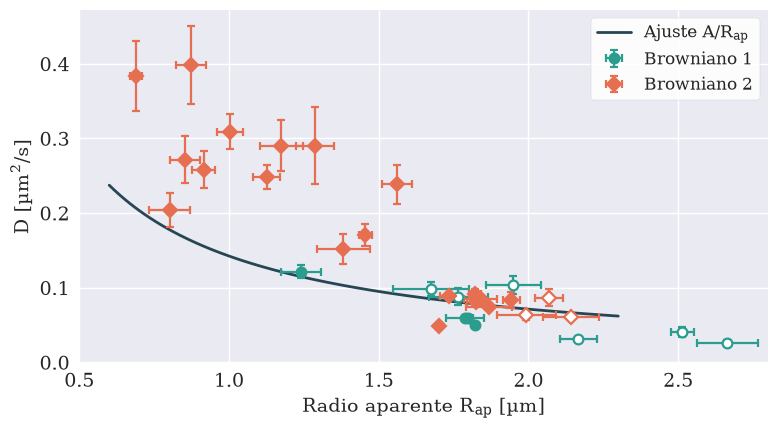

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ajustes = {}
for nombre, color, fmt in (("BROWNIANO 1", SERIE1, "o"), ("BROWNIANO 2", SERIE2, "D")):
    M = MED[nombre]
    D = RES[nombre, "recta por partícula"]["D_i"]
    eD = D * M["err_rel_D"]
    Rap, eR = M["Rap"][M["libres"]], M["eRap"][M["libres"]]
    una = np.isin(M["clase_l"], ["sola", "chica"])
    ax.errorbar(Rap[una], D[una], eD[una], eR[una], fmt=fmt, color=color, mfc=color, mec=color, label=nombre.capitalize(), **MARCA)
    ax.errorbar(Rap[~una], D[~una], eD[~una], eR[~una], fmt=fmt, color=color, mfc="white", mec=color, **MARCA)
    # D = A / R (un parámetro) y D = B R^(-p) (exponente libre), pesados por el error de D
    A = np.sum(D[una] / Rap[una] / eD[una] ** 2) / np.sum(1 / Rap[una] ** 2 / eD[una] ** 2)
    if nombre == "BROWNIANO 2":
        (p, lnB), cov = np.polyfit(np.log(Rap[una]), np.log(D[una]), 1, w=D[una] / eD[una], cov=True)
        rho, pval = stats.spearmanr(Rap[una], D[una])
        ajustes[nombre] = dict(n=int(una.sum()), A=A, exponente=-p, err_exponente=np.sqrt(cov[0, 0]), spearman=rho, p_spearman=pval,
                               chi2_red_1_sobre_R=np.sum(((D[una] - A / Rap[una]) / eD[una]) ** 2) / (una.sum() - 1))
        rr = np.linspace(0.6, 2.3, 100)
        ax.plot(rr, A / rr, color=AJUSTE, lw=2, zorder=2, label=r"Ajuste $A/R_{ap}$")
ax.set_xlabel(r"Radio aparente $R_{ap}$ [µm]")
ax.set_ylabel(r"$D$ [µm$^2$/s]")
ax.set_xlim(0.5, 2.8); ax.set_ylim(0, None)
ax.legend(loc="upper right", fontsize=12, **LEYENDA)
guardar(fig, "D_vs_radio")

salida_part = tabla_part.copy()
salida_part.columns = ["medicion", "particula", "clase", "cuadros", "R_ap_um", "err_R_ap_um", "alfa", "deriva_um_s", "D_recta_um2_s"]
for nombre, M in MED.items():                      # D con el método de la recta, corregido por la simulación gemela
    esta = (salida_part.medicion == nombre) & salida_part.particula.isin(M["ids_l"])
    salida_part.loc[esta, "D_recta_um2_s"] = RES[nombre, "recta por partícula"]["D_i"]
    salida_part.loc[esta, "err_D_recta_um2_s"] = RES[nombre, "recta por partícula"]["D_i"] * M["err_rel_D"]
salida_part.to_csv(os.path.join(SALIDA, "particulas.csv"), index=False, float_format="%.5g")
for nombre, a in ajustes.items():
    print("%s, %d partículas sueltas (del tamaño nominal y chicas): D ∝ R_ap^(-%.2f ± %.2f) | Spearman %.2f (p = %.1g) | "
          "A = %.3f µm³/s, chi² reducido del ajuste A/R: %.1f" % (nombre, a["n"], a["exponente"], a["err_exponente"],
                                                                  a["spearman"], a["p_spearman"], a["A"], a["chi2_red_1_sobre_R"]))
for nombre in ("BROWNIANO 1", "BROWNIANO 2"):
    M = MED[nombre]
    D = RES[nombre, "recta por partícula"]["D_i"]
    print(nombre + ": D medio por clase [µm²/s]: " + ", ".join(
        "%s %.3f (n = %d)" % (c, D[M["clase_l"] == c].mean(), (M["clase_l"] == c).sum()) for c in pd.unique(M["clase_l"])))

## Conclusión

**$D$ de cada medición** (beads solas, recta por partícula, corregido con la simulación gemela):

| Medición | Beads | $D$ [µm²/s] | Contra Stokes–Einstein ($R$ = 1.5 µm, 23 °C) |
|---|---|---|---|
| BROWNIANO 1 | 3 | 0.056 ± 0.004 | 0.71 veces el de la receta del cuaderno (24 % de glicerina en masa: 0.079; 0.072 a 0.087 entre 20 y 26 °C) |
| BROWNIANO 2 | 7 | 0.079 ± 0.007 | 4.6 veces el de la receta del cuaderno (58 %: 0.017). Es el de 24 % |
| GROS BROWNIANO | 11 | 0.169 ± 0.007, con la escala supuesta | 1.09 veces el del agua (0.155); igual al del agua a 26 °C |
| CHICAS BROWNIANO | 26 | 0.102 ± 0.010, con la escala y el tiempo supuestos | 0.66 veces el del agua |

La incerteza suma en cuadratura la dispersión entre partículas, el rango entre métodos de deriva, el rango según cuántos retardos se ajustan y la escala (solo en las nuestras). La que manda es la dispersión entre partículas.

**La deriva.**

1. Sin restarla, $D$ de las beads solas sale de más: 5 % en BROWNIANO 1, 11 % en BROWNIANO 2, 2 % en GROS y 27 % en CHICAS. Con todas las partículas libres de BROWNIANO 1, 36 %. La pendiente log-log del MSD pasa de 1.10–1.37 a 0.93–1.06.
2. Restar la **recta de cada partícula** alcanza en las cuatro y es lo que se recomienda. Le saca al browniano 1 % (2.6 % en CHICAS, por las trayectorias cortas), medido con la simulación gemela y corregido.
3. La **deriva común** y los **pares** solo sirven con muchas partículas iguales a la vez (GROS, CHICAS). En BROWNIANO 1 fallan porque cada partícula deriva a su velocidad; en BROWNIANO 2 la deriva común necesita una corrección de 7 % porque mezcla partículas de $D$ muy distinto.
4. La **media móvil** saca cualquier deriva lenta pero se lleva 4 a 7 % del browniano con ventanas de 10 s (4 s en CHICAS) y entre un tercio y la mitad con 1 s. Corregida con la gemela, da el mismo $D$ con ventanas de 1 a 40 s en BROWNIANO 1, BROWNIANO 2 y GROS (dentro de 4 %): es la prueba de que lo que hay es un browniano más una deriva lenta, y de que la recta no deja deriva sin sacar.
5. El **ajuste con el término $v^2\tau^2$** da lo mismo que la recta sin tocar las trayectorias.

**¿Es browniano?** En BROWNIANO 1, BROWNIANO 2 y GROS, sí: MSD lineal ($\alpha$ = 0.93 ± 0.04, 0.96 ± 0.02 y 1.06 ± 0.02), pasos isótropos ($\sigma_y/\sigma_x$ de 0.97 a 1.03) y gaussianos una vez que se normaliza con la $\sigma$ local (curtosis 0.02, 0.01 y 0.16). La correlación entre pasos seguidos es la que corresponde a la ordenada del MSD: negativa en las nuestras (−0.14 y −0.05; ruido de localización de 55 y 33 nm) y positiva en GROS (+0.13; equivale a una exposición de 0.6 veces el período entre cuadros). En CHICAS el MSD es lineal ($\alpha$ = 1.05 ± 0.02) pero los pasos **no** son gaussianos (curtosis 7.9; la mitad de los pasos mide menos de 0.34 px y 2.5 % más de 3 px) ni isótropos (1.17 ± 0.04): la compresión del MP4 deja quieta la imagen de cada bead varios cuadros y después la actualiza de golpe. De ese video solo se le puede creer al MSD.

**Tamaños.** El radio aparente de las beads solas es parecido en las cuatro mediciones (1.80 a 1.91 µm de media), unos 0.3 a 0.4 µm más que el nominal. BROWNIANO 2 tiene partículas de 0.7 a 2.1 µm de radio aparente y $D$ baja con el tamaño (correlación de rangos −0.83, $p$ = 10⁻⁵, 19 partículas), pero más rápido que $1/R$: $D \propto R_{ap}^{-1.9 \pm 0.3}$. Los agregados difunden más despacio que las beads solas (0.033 contra 0.056 µm²/s en BROWNIANO 1; 0.062 contra 0.079 en BROWNIANO 2). Eso explica por qué $D$ variaba tanto entre trayectorias en BROWNIANO 1: de las 10 libres, 3 son beads solas en foco, 3 son agregados, 1 es una partícula chica y 3 están desenfocadas (otra altura: $D$ = 0.096 µm²/s y deriva cuatro veces más rápida).

**Lo que no se puede afirmar**

- **Qué muestra es BROWNIANO 2.** Con 58 % de glicerina $D$ tendría que ser 0.017 µm²/s y se mide 0.079. La pared solo puede bajar $D$, y haría falta una temperatura de unos 70 °C. El valor medido es el de una mezcla de 24 % (0.079), que es la receta anotada para BROWNIANO 1. O la anotación del cuaderno no corresponde a esta grabación, o la mezcla no era esa.
- **Por qué BROWNIANO 1 da 0.71 del teórico.** Lo explicaría una bead con su superficie a 1.4 µm del vidrio (Faxén), o 34 % de glicerina en vez de 24 %, o beads más grandes que 3 µm. La altura no se midió y la receta tiene un signo de pregunta: no se puede elegir.
- **Por qué $D$ cae más rápido que $1/R$.** Puede ser que el radio aparente exagere el de las partículas chicas menos que el de las grandes, o que las beads grandes estén más cerca del vidrio. No hay cómo separarlo.
- **Los valores de los otros grupos en µm.** La escala es supuesta. El tamaño aparente de sus beads coincide con el de las nuestras dentro de 5 %, que en $D$ son 10 %. En CHICAS además el tiempo sale de interpretar los cuadros repetidos: si no faltara ninguno, $D$ sería 12 % menor.
- **Cuadros perdidos.** Los TIFF no traen el tiempo de cada cuadro: salvo la pausa de BROWNIANO 1, no se puede saber si falta alguno.
- **BROWNIANO 1 tiene solo 3 beads solas.** Su error estadístico (6 %) sale de tres valores.

Cuánto dato entró: BROWNIANO 1, 11 trayectorias de 43 (10 libres, 3 beads solas); BROWNIANO 2, 22 de 43 (22 libres, 7 solas); GROS, 13 de 24 (13 libres, 11 solas); CHICAS, 32 de 74 (30 libres, 26 solas). Las dudas y las decisiones, con su impacto, están en `DUDAS browniano.md`.